# kp-MoSeq workflow for DLC output

This notebook runs a kp-MoSeq workflow using selected DeepLabCut `.h5/.hdf5` files.

Key points:
- Select the `.h5/.hdf5` files yourself using a file picker.
- Extra `.h5` files in the DLC `videos` folder are ignored.
- Original videos stay in the DLC `videos` folder.
- Head-fixed mode can be switched on/off.
- Fitting uses a two-stage workflow: AR-HMM fitting, then full model fitting.
- Plots are saved as PNG where possible.
- Each run is saved inside a date folder such as `260710/run_HHMMSS/`.

In [1]:
# =========================
# 0. Imports and global settings
# =========================

import os
# Must be set before importing jax / jax_moseq / keypoint_moseq
os.environ["XLA_PYTHON_CLIENT_PREALLOCATE"] = "false"
os.environ["XLA_PYTHON_CLIENT_MEM_FRACTION"] = "0.85"
os.environ["TF_GPU_ALLOCATOR"] = "cuda_malloc_async"

# (Now import jax)
#import jax
#jax.config.update("jax_enable_x64", False)

# Important: set JAX precision before importing keypoint_moseq.
import jax
jax.config.update("jax_enable_x64", False)

from pathlib import Path
from datetime import datetime
import shutil
from contextlib import contextmanager

import matplotlib.pyplot as plt
import keypoint_moseq as kpms
import numpy as np

In [2]:
# =========================
# 1. User settings
# =========================
# Use forward slashes in Windows paths to avoid escape-character problems.

# Base output folder for all kp-MoSeq analyses.
# Each run is saved under a date folder such as C:/Keypoint-MoSeq/260710/run_153000/.
output_root = Path("G:/OFT_DLCv3_kpmoseq/kpmoseq_result")

# Date folder name.
# Default: YYMMDD based on the computer date, e.g. 260710.
# You can also manually set it, e.g. RUN_DATE = "260710".
RUN_DATE = datetime.now().strftime("%y%m%d")

# Run folder name inside the date folder.
# Keeping a time stamp prevents overwriting if you run kp-MoSeq more than once on the same day.
RUN_ID = datetime.now().strftime("run_%H%M%S")

# Main output folders for this run.
daily_dir = output_root / RUN_DATE
run_dir = daily_dir / RUN_ID
project_dir = run_dir / "kp_moseq_project"

# Selected .h5 files are copied here automatically.
# kp-MoSeq reads only this folder.
selected_data_dir = run_dir / "selected_input"

# DLC project config.yaml
# Change this to your DLC project's config.yaml.
dlc_config = "G:/OFT_DLCv3_kpmoseq/260707_OFT-QA-2026-07-07/config.yaml"

# Folder containing original DLC-analyzed videos.
# This folder can contain many .h5 files; you will manually select only the .h5 files to analyze.
dlc_video_dir = Path("G:/OFT_DLCv3_kpmoseq/WT_AQP4_Allday")

# Use a Windows file selection dialog to choose .h5/.hdf5 files.
# If the dialog does not appear in VS Code/Jupyter, set USE_FILE_DIALOG=False and fill SELECTED_H5_FILES manually.
USE_FILE_DIALOG = True

# Manual fallback. Used only when USE_FILE_DIALOG=False.
# Example:
# SELECTED_H5_FILES = [
#     "C:/DLC/project/videos/video1DLC_...h5",
#     "C:/DLC/project/videos/video2DLC_...h5",
# ]
SELECTED_H5_FILES = []

# Bodyparts used to define animal orientation.
# Use exact DLC bodypart names.
anterior_bodyparts = ["nose", "ear_R", "ear_L"]
posterior_bodyparts = ["tail_base"]

# Head-fixed switch.
# False: normal/free-moving style alignment using anterior/posterior bodyparts.
# True : head-fixed setting; kp-MoSeq uses fixed heading instead of estimating heading from body axis.
HEAD_FIXED = False

# Fitting mode.
# "standard": AR-HMM 50 + full model 200 additional iterations.
# "full"    : AR-HMM 50 + full model 500 additional iterations.
RUN_MODE = "full"  # choose: "standard" or "full"

FIT_SETTINGS = {
    "standard": {"num_ar_iters": 50, "num_full_iters": 200},
    "full": {"num_ar_iters": 50, "num_full_iters": 500},
}

if RUN_MODE not in FIT_SETTINGS:
    raise ValueError(f"RUN_MODE must be one of {list(FIT_SETTINGS.keys())}, got {RUN_MODE!r}")

num_ar_iters = FIT_SETTINGS[RUN_MODE]["num_ar_iters"]
num_full_iters = FIT_SETTINGS[RUN_MODE]["num_full_iters"]

# Optional hyperparameter update sometimes used after AR-HMM fitting.
# Keep False unless you intentionally want to modify syllable duration behavior.
#APPLY_KAPPA_UPDATE = False
#KAPPA = 1e4

print("RUN_DATE:", RUN_DATE)
print("RUN_ID:", RUN_ID)
print("daily_dir:", daily_dir)
print("run_dir:", run_dir)
print("project_dir:", project_dir)
print("selected_data_dir:", selected_data_dir)
print("RUN_MODE:", RUN_MODE)
print("HEAD_FIXED:", HEAD_FIXED)
print("num_ar_iters:", num_ar_iters)
print("num_full_iters:", num_full_iters)

RUN_DATE: 260924
RUN_ID: run_111227
daily_dir: G:\OFT_DLCv3_kpmoseq\kpmoseq_result\260924
run_dir: G:\OFT_DLCv3_kpmoseq\kpmoseq_result\260924\run_111227
project_dir: G:\OFT_DLCv3_kpmoseq\kpmoseq_result\260924\run_111227\kp_moseq_project
selected_data_dir: G:\OFT_DLCv3_kpmoseq\kpmoseq_result\260924\run_111227\selected_input
RUN_MODE: full
HEAD_FIXED: False
num_ar_iters: 50
num_full_iters: 500


In [3]:
# =========================
# 2. Helper functions
# =========================
@contextmanager
def save_matplotlib_figures_as_png(dpi=300):
    """Redirect Matplotlib .pdf save paths to .png."""
    original_savefig = plt.savefig

    def savefig_png(path, *args, **kwargs):
        path = Path(path)
        if path.suffix.lower() == ".pdf":
            path = path.with_suffix(".png")
        kwargs.setdefault("dpi", dpi)
        kwargs.setdefault("bbox_inches", "tight")
        return original_savefig(str(path), *args, **kwargs)

    plt.savefig = savefig_png
    try:
        yield
    finally:
        plt.savefig = original_savefig


def select_h5_files_with_dialog(initial_dir):
    """Open a file picker and return selected .h5/.hdf5 files."""
    import tkinter as tk
    from tkinter import filedialog

    root = tk.Tk()
    root.withdraw()
    root.attributes("-topmost", True)

    file_paths = filedialog.askopenfilenames(
        title="Select DLC .h5/.hdf5 files for kp-MoSeq",
        initialdir=str(initial_dir),
        filetypes=[("DLC h5 files", "*.h5 *.hdf5"), ("All files", "*.*")],
    )

    root.destroy()
    return [Path(p) for p in file_paths]


def prepare_selected_h5_input():
    """Copy selected h5 files into selected_data_dir and return the folder path."""
    if USE_FILE_DIALOG:
        selected_h5_files = select_h5_files_with_dialog(dlc_video_dir)
    else:
        selected_h5_files = [Path(p) for p in SELECTED_H5_FILES]

    if len(selected_h5_files) == 0:
        raise ValueError("No .h5/.hdf5 files were selected.")

    missing = [p for p in selected_h5_files if not p.exists()]
    if missing:
        missing_text = "\n".join(str(p) for p in missing)
        raise FileNotFoundError("Selected files do not exist:\n" + missing_text)

    selected_data_dir.mkdir(parents=True, exist_ok=True)

    # Clean old selected input files only inside selected_data_dir.
    for old_file in selected_data_dir.glob("*"):
        if old_file.is_file():
            old_file.unlink()

    for src_file in selected_h5_files:
        shutil.copy2(src_file, selected_data_dir / src_file.name)

    print("Selected h5 files:")
    for f in selected_h5_files:
        print("-", f.name)

    print("\nCopied selected h5 files to:", selected_data_dir)
    return selected_data_dir


def build_video_paths_from_results(results, video_dir):
    """Match each results key to an mp4 video in video_dir."""
    video_dir = Path(video_dir)
    video_paths = {}

    for key in results.keys():
        # First try videos whose names start with the full kp-MoSeq recording key.
        candidates = list(video_dir.glob(f"{key}*.mp4"))

        # If no labeled video exists, try removing a common DLC suffix from the key.
        if len(candidates) == 0 and "DLC_" in key:
            base_name = key.split("DLC_")[0]
            candidates = list(video_dir.glob(f"{base_name}*.mp4"))

        if len(candidates) > 0:
            video_paths[key] = str(candidates[0])
            print("Matched:", key, "->", candidates[0].name)
        else:
            print("Missing video for:", key)

    print("\nMatched videos:", len(video_paths), "/", len(results))
    return video_paths

In [4]:
# =========================
# 3. Select h5 files and define input paths
# =========================
keypoint_data_path = prepare_selected_h5_input()
video_dir = dlc_video_dir

print("\nPath checks")
print("daily_dir exists:", daily_dir.exists(), daily_dir)
print("run_dir exists:", run_dir.exists(), run_dir)
print("project_dir exists:", project_dir.exists(), project_dir)
print("keypoint_data_path exists:", keypoint_data_path.exists(), keypoint_data_path)
print("video_dir exists:", video_dir.exists(), video_dir)
print("dlc_config exists:", Path(dlc_config).exists(), dlc_config)

Selected h5 files:
- day1_260113_COC_AQP03DLC_Resnet50_260707_OFTJul7shuffle3_snapshot_best-80_filtered.h5
- day1_260113_COC_WT01DLC_Resnet50_260707_OFTJul7shuffle3_snapshot_best-80_filtered.h5
- day2_260114_COC_AQP03DLC_Resnet50_260707_OFTJul7shuffle3_snapshot_best-80_filtered.h5
- day2_260114_COC_WT01DLC_Resnet50_260707_OFTJul7shuffle3_snapshot_best-80_filtered.h5
- day3_260115_COC_AQP03DLC_Resnet50_260707_OFTJul7shuffle3_snapshot_best-80_filtered.h5
- day3_260115_COC_WT01DLC_Resnet50_260707_OFTJul7shuffle3_snapshot_best-80_filtered.h5
- day4_260116_COC_AQP03DLC_Resnet50_260707_OFTJul7shuffle3_snapshot_best-80_filtered.h5
- day4_260116_COC_WT01DLC_Resnet50_260707_OFTJul7shuffle3_snapshot_best-80_filtered.h5
- day5_260117_COC_AQP03DLC_Resnet50_260707_OFTJul7shuffle3_snapshot_best-80_filtered.h5
- day5_260117_COC_WT01DLC_Resnet50_260707_OFTJul7shuffle3_snapshot_best-80_filtered.h5

Copied selected h5 files to: G:\OFT_DLCv3_kpmoseq\kpmoseq_result\260924\run_111227\selected_input

Path c

In [5]:
# =========================
# 4. Setup kp-MoSeq project/config
# =========================
project_dir.mkdir(parents=True, exist_ok=True)

kpms.setup_project(
    project_dir,
    deeplabcut_config=dlc_config,
    overwrite=True,
)

# Update config with confidence threshold and bodyparts
kpms.update_config(
    project_dir,
    video_dir=str(keypoint_data_path),
    anterior_bodyparts=anterior_bodyparts,
    posterior_bodyparts=posterior_bodyparts,
    fix_heading=HEAD_FIXED,
    conf_threshold=0.9,  # Set confidence threshold here
    latent_dim=6,  # Reduces SLDS transition tensor size
)

config = kpms.load_config(project_dir)

print("Project setup complete")
print("Project dir:", project_dir)
print("video_dir:", config["video_dir"])
print("bodyparts:", config["bodyparts"])
print("use_bodyparts:", config["use_bodyparts"])
print("anterior:", config["anterior_bodyparts"])
print("posterior:", config["posterior_bodyparts"])
print("fix_heading:", config.get("fix_heading", None))

Project setup complete
Project dir: G:\OFT_DLCv3_kpmoseq\kpmoseq_result\260924\run_111227\kp_moseq_project
video_dir: G:\OFT_DLCv3_kpmoseq\kpmoseq_result\260924\run_111227\selected_input
bodyparts: ['nose', 'ear_R', 'ear_L', 'neck', 'back_1', 'back_2', 'back_3', 'tail_base']
use_bodyparts: ['nose', 'ear_R', 'ear_L', 'neck', 'back_1', 'back_2', 'back_3', 'tail_base']
anterior: ['nose', 'ear_R', 'ear_L']
posterior: ['tail_base']
fix_heading: False


In [6]:
# =========================
# 5. Load DLC keypoint data
# =========================
coordinates, confidences, bodyparts = kpms.load_keypoints(
    str(keypoint_data_path),
    "deeplabcut",
)

print("DLC data loaded")
print("bodyparts:")
print(bodyparts)

print("\nRecordings:")
for name, data_array in coordinates.items():
    print(name, data_array.shape)

Loading keypoints: 100%|████████████████| 10/10 [00:00<00:00, 34.58it/s]


DLC data loaded
bodyparts:
['nose', 'ear_R', 'ear_L', 'neck', 'back_1', 'back_2', 'back_3', 'tail_base']

Recordings:
day1_260113_COC_AQP03DLC_Resnet50_260707_OFTJul7shuffle3_snapshot_best-80_filtered (54317, 8, 2)
day1_260113_COC_WT01DLC_Resnet50_260707_OFTJul7shuffle3_snapshot_best-80_filtered (54316, 8, 2)
day2_260114_COC_AQP03DLC_Resnet50_260707_OFTJul7shuffle3_snapshot_best-80_filtered (54237, 8, 2)
day2_260114_COC_WT01DLC_Resnet50_260707_OFTJul7shuffle3_snapshot_best-80_filtered (54447, 8, 2)
day3_260115_COC_AQP03DLC_Resnet50_260707_OFTJul7shuffle3_snapshot_best-80_filtered (54317, 8, 2)
day3_260115_COC_WT01DLC_Resnet50_260707_OFTJul7shuffle3_snapshot_best-80_filtered (54244, 8, 2)
day4_260116_COC_AQP03DLC_Resnet50_260707_OFTJul7shuffle3_snapshot_best-80_filtered (54314, 8, 2)
day4_260116_COC_WT01DLC_Resnet50_260707_OFTJul7shuffle3_snapshot_best-80_filtered (54140, 8, 2)
day5_260117_COC_AQP03DLC_Resnet50_260707_OFTJul7shuffle3_snapshot_best-80_filtered (54240, 8, 2)
day5_260117_C

In [7]:
# =========================
# 6. Format data for kp-MoSeq
# =========================
data, metadata = kpms.format_data(
    coordinates,
    confidences,
    **config,
)

print("Data formatted successfully")
print("data keys:", data.keys())
print("metadata type:", type(metadata))

Data formatted successfully
data keys: dict_keys(['Y', 'conf', 'mask'])
metadata type: <class 'tuple'>


In [8]:
import numpy as np

# Convert data['Y'] to a NumPy array and check for NaNs
total_nans = np.isnan(np.array(data['Y'])).sum()
total_infs = np.isinf(np.array(data['Y'])).sum()

print("Total NaNs remaining in data['Y']:", total_nans)
print("Total Infs remaining in data['Y']:", total_infs)
print("Shape of data['Y']:", data['Y'].shape)

Total NaNs remaining in data['Y']: 0
Total Infs remaining in data['Y']: 0
Shape of data['Y']: (60, 10030, 8, 2)


In [9]:
# =========================
# 7. Fit PCA
# =========================
pca = kpms.fit_pca(
    **data,
    **config,
)

kpms.save_pca(pca, project_dir)

print("PCA fitting complete")
print("PCA saved to:", project_dir / "pca.p")

PCA fitting complete
PCA saved to: G:\OFT_DLCv3_kpmoseq\kpmoseq_result\260924\run_111227\kp_moseq_project\pca.p


>=90.0% of variance exlained by 7 components.


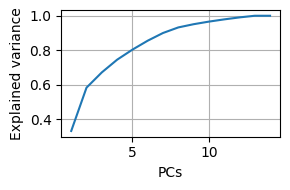

Temporarily saved: G:\OFT_DLCv3_kpmoseq\kpmoseq_result\260924\run_111227\kp_moseq_project\pca_scree.png


In [10]:
# =========================
# 8. Create PCA scree plot
# =========================
kpms.print_dims_to_explain_variance(pca, 0.9)

fig = kpms.plot_scree(pca, savefig=False)

# model_name is not available yet, so save temporarily here.
temporary_pca_scree_path = project_dir / "pca_scree.png"
fig.savefig(temporary_pca_scree_path, dpi=300, bbox_inches="tight")
plt.close(fig)

print("Temporarily saved:", temporary_pca_scree_path)


In [11]:
# =========================
# 8b. Ensure JAX/data precision compatibility
# =========================
# This avoids errors such as:
# 'JAX is configured to use 64-bit precision, but data contains 32-bit arrays'
from jax_moseq.utils.debugging import convert_data_precision

data = convert_data_precision(data)

print("Data precision converted to match the current JAX configuration")

Data precision converted to match the current JAX configuration


In [12]:
# =========================
# 9. Initialize model
# =========================
model = kpms.init_model(
    data,
    pca=pca,
    **config,
)

print("Model initialized")

Model initialized


In [14]:
# ==========================================================
# 10. Automated Kappa Scan
# ==========================================================
kappas = np.logspace(3, 7, 5)  # [1e3, 1e4, 1e5, 1e6, 1e7]
decrease_kappa_factor = 10
prefix = "kappa_scan"
kappa_model_names = {}

print("Starting Kappa scan across:", kappas)

for kappa in kappas:
    model_name = f"{prefix}_{kappa:.0e}"
    kappa_model_names[kappa] = model_name
    print(f"\n--- Training {model_name} (kappa={kappa:.1e}) ---")

    # Initialize a fresh model instance for this scan parameter
    current_model = kpms.init_model(data, pca=pca, **config)

    # Stage 1: Fit AR-only model
    current_model = kpms.update_hypparams(current_model, kappa=kappa)
    current_model, _ = kpms.fit_model(
        current_model,
        data,
        metadata,
        project_dir,
        model_name,
        ar_only=True,
        num_iters=num_ar_iters,
        save_every_n_iters=25,
        generate_progress_plots=False,
    )

    # Stage 2: Fit Full Model with adjusted kappa
    current_model = kpms.update_hypparams(current_model, kappa=kappa / decrease_kappa_factor)
    current_model, _ = kpms.fit_model(
        current_model,
        data,
        metadata,
        project_dir,
        model_name,
        ar_only=False,
        start_iter=num_ar_iters,
        num_iters=num_ar_iters + num_full_iters,
        save_every_n_iters=25,
        generate_progress_plots=False,
    )

Starting Kappa scan across: [1.e+03 1.e+04 1.e+05 1.e+06 1.e+07]

--- Training kappa_scan_1e+03 (kappa=1.0e+03) ---
Outputs will be saved to G:\OFT_DLCv3_kpmoseq\kpmoseq_result\260924\ru
n_111227\kp_moseq_project\kappa_scan_1e+03


100%|███████████████████████████████████| 51/51 [06:59<00:00,  8.22s/it]


Outputs will be saved to G:\OFT_DLCv3_kpmoseq\kpmoseq_result\260924\ru
n_111227\kp_moseq_project\kappa_scan_1e+03


100%|███████████████████████████████| 501/501 [3:37:49<00:00, 26.09s/it]



--- Training kappa_scan_1e+04 (kappa=1.0e+04) ---
Outputs will be saved to G:\OFT_DLCv3_kpmoseq\kpmoseq_result\260924\ru
n_111227\kp_moseq_project\kappa_scan_1e+04


100%|███████████████████████████████████| 51/51 [06:52<00:00,  8.09s/it]


... (10 outputs left out)


--- Training kappa_scan_1e+07 (kappa=1.0e+07) ---
Outputs will be saved to G:\OFT_DLCv3_kpmoseq\kpmoseq_result\260924\ru
n_111227\kp_moseq_project\kappa_scan_1e+07


100%|███████████████████████████████████| 51/51 [06:52<00:00,  8.09s/it]


Outputs will be saved to G:\OFT_DLCv3_kpmoseq\kpmoseq_result\260924\ru
n_111227\kp_moseq_project\kappa_scan_1e+07


100%|███████████████████████████████| 501/501 [3:37:49<00:00, 26.09s/it]


In [18]:
# Run this once in a cell before Section 11 to fix existing folder names:
for kappa in kappas:
    old_dir = project_dir / f"{prefix}_{kappa:.0e}"
    new_dir = project_dir / f"{prefix}-{kappa}"
    if old_dir.exists() and not new_dir.exists():
        old_dir.rename(new_dir)
        print(f"Renamed: {old_dir.name} -> {new_dir.name}")

Renamed: kappa_scan_1e+03 -> kappa_scan-1000.0
Renamed: kappa_scan_1e+04 -> kappa_scan-10000.0
Renamed: kappa_scan_1e+05 -> kappa_scan-100000.0
Renamed: kappa_scan_1e+06 -> kappa_scan-1000000.0
Renamed: kappa_scan_1e+07 -> kappa_scan-10000000.0


In [19]:
# ==========================================================
# 11. Plot Kappa Scan Diagnostics & Model Selection
# ==========================================================
# Generate and save the kappa scan diagnostic plot (Median Duration vs Iteration / Kappa)
fig = kpms.plot_kappa_scan(kappas, project_dir, prefix)
kappa_plot_path = project_dir / f"{prefix}_convergence.png"
if fig is not None:
    plt.savefig(kappa_plot_path, dpi=300, bbox_inches="tight")
    plt.close()
else:
    # If returned plot saves directly to current figure
    plt.savefig(kappa_plot_path, dpi=300, bbox_inches="tight")
    plt.close()

print(f"\nKappa scan diagnostic plot saved to: {kappa_plot_path}")

# --- SELECT OPTIMAL KAPPA ---
# Target typical mouse behavioral syllable durations (approx. 300-400 ms, or 9-12 frames at 30 Hz).
# Set your chosen kappa here based on the generated plot:
OPTIMAL_KAPPA = 1e6  # Adjust to the chosen scan value
model_name = kappa_model_names[OPTIMAL_KAPPA]
print(f"Selected optimal model: {model_name} (kappa={OPTIMAL_KAPPA:.1e})")

Loading checkpoints: 100%|██████████| 5/5 [00:15<00:00,  3.16s/it]



Kappa scan diagnostic plot saved to: G:\OFT_DLCv3_kpmoseq\kpmoseq_result\260924\run_111227\kp_moseq_project\kappa_scan_convergence.png
Selected optimal model: kappa_scan_1e+06 (kappa=1.0e+06)


In [22]:
# ==========================================================
# 12. Reindex Selected Model Checkpoint
# ==========================================================
OPTIMAL_KAPPA = 1e6  # 1000000.0
prefix = "kappa_scan"

# Ensure model_name matches the folder on disk (kappa_scan-1000000.0)
model_name = f"{prefix}-{OPTIMAL_KAPPA}"

# Reindex the selected model so syllable 0 is the most frequent
kpms.reindex_syllables_in_checkpoint(
    project_dir,
    model_name,
)
print(f"Syllables reindexed by frequency for {model_name}")

# Re-link model_output_dir for downstream stages (13b to 20 remain unchanged)
model_output_dir = project_dir / model_name
model_output_dir.mkdir(parents=True, exist_ok=True)

Reindexing: 100%|███████████| 23/23 [01:08<00:00,  2.98s/model snapshot]

Syllables reindexed by frequency for kappa_scan-1000000.0


In [23]:
# ==========================================================
# 13b. Apply the fitted model across ALL 60 recordings
# ==========================================================
import pandas as pd
import numpy as np
from pathlib import Path

all_data_dir = Path(dlc_video_dir)
results_dir = model_output_dir / "results_all_sessions"
results_dir.mkdir(parents=True, exist_ok=True)
all_results_h5 = results_dir / "results.h5"

# ----------------------------------------------------------
# Check if inference already ran to avoid redundant computation
# ----------------------------------------------------------
if all_results_h5.exists():
    print(f"Found existing inference results at: {all_results_h5}")
    print("Loading results directly from disk...")
    all_results = kpms.load_results(project_dir, model_name, results_path=str(all_results_h5))
else:
    print(f"Loading DLC .h5 files from: {all_data_dir}")

    # 1. Load keypoints from folder
    raw_coordinates, raw_confidences, _ = kpms.load_keypoints(
        str(all_data_dir),
        format="deeplabcut",
        extension="h5",
        recursive=False,
        path_in_name=False,
    )

    # 2. Filter dictionaries to keep ONLY recordings ending with '_filtered'
    all_coordinates = {
        k: v for k, v in raw_coordinates.items() if k.endswith("_filtered")
    }
    all_confidences = {
        k: v for k, v in raw_confidences.items() if k.endswith("_filtered")
    }

    print(f"Isolated {len(all_coordinates)} filtered recordings.")
    assert len(all_coordinates) == 60, f"Expected 60 files, but found {len(all_coordinates)}."

    # 3. Format full dataset using the project's config
    all_data, all_metadata = kpms.format_data(
        all_coordinates,
        all_confidences,
        **config,
    )

    # 4. Match array precision to JAX configuration (float32)
    all_data = convert_data_precision(all_data)

    # 5. Load the trained, reindexed model checkpoint
    model, _, _, _ = kpms.load_checkpoint(
        project_dir,
        model_name,
    )

    # 6. Apply the frozen model across all 60 recordings
    print("Running inference across all 60 recordings...")
    all_results = kpms.apply_model(
        model,
        all_data,
        all_metadata,
        project_dir=project_dir,
        model_name=model_name,
        pca=pca,                         # Provides the noise prior / error model
        results_path=str(all_results_h5),# Saves results.h5 directly to custom folder
        num_iters=25,                    # 20-30 iterations is sufficient and cuts runtime by ~50%
        batch_size=5,                    # Keep low to stay safely within 8 GB VRAM
        parallel_message_passing=False,  # Sequential mode prevents GPU OOM errors
        **config,                        # Passes bodypart indices and confidence thresholds
    )
    print("Inference complete.")

Loading DLC .h5 files from: G:\OFT_DLCv3_kpmoseq\WT_AQP4_Allday


Loading keypoints: 100%|██████████████| 120/120 [00:30<00:00,  3.95it/s]


Isolated 60 filtered recordings.
Running inference across all 60 recordings...


Applying model: 100%|████████████████| 25/25 [1:57:28<00:00, 281.96s/it]


Saved results to G:\OFT_DLCv3_kpmoseq\kpmoseq_result\260924\run_111227
\kp_moseq_project\kappa_scan-1000000.0\results_all_sessions\results.h5
Inference complete.


In [24]:
# ----------------------------------------------------------
# 7. Save frame-by-frame CSVs (syllables, centroid, heading, latents)
# ----------------------------------------------------------

import pandas as pd
import numpy as np

print(f"Exporting per-session CSVs to: {results_dir}")

for session_name, res in all_results.items():
    df_dict = {}

    # 1. Syllable (Column A) - Search all possible kpms keys
    syllable_arr = None
    for k in ["syllable", "syllables", "z"]:
        if k in res:
            syllable_arr = res[k]
            break
    if syllable_arr is None and "states" in res and isinstance(res["states"], dict):
        for k in ["z", "syllable", "syllables"]:
            if k in res["states"]:
                syllable_arr = res["states"][k]
                break

    if syllable_arr is not None:
        df_dict["syllable"] = np.asarray(syllable_arr).squeeze().astype(int)
    else:
        print(f"Warning: No syllable array found for {session_name}")

    # 2. Centroid coordinates (Columns B & C)
    if "centroid" in res:
        cen = np.asarray(res["centroid"])
        if cen.ndim == 2 and cen.shape[1] >= 2:
            df_dict["centroid_x"] = cen[:, 0]
            df_dict["centroid_y"] = cen[:, 1]

    # 3. Heading (Column D)
    if "heading" in res:
        df_dict["heading"] = np.asarray(res["heading"]).squeeze()

    # 4. Latent states formatted as 'latent_state_0', 'latent_state_1', ...
    lat_arr = None
    for k in ["latent_state", "latents", "x"]:
        if k in res:
            lat_arr = res[k]
            break
    if lat_arr is None and "states" in res and isinstance(res["states"], dict):
        for k in ["x", "latent_state", "latents"]:
            if k in res["states"]:
                lat_arr = res["states"][k]
                break

    if lat_arr is not None:
        lat = np.asarray(lat_arr)
        if lat.ndim == 2:
            for d in range(lat.shape[1]):
                df_dict[f"latent_state_{d}"] = lat[:, d]

    # Export without index column to match target layout exactly
    df = pd.DataFrame(df_dict)
    df.to_csv(results_dir / f"{session_name}.csv", index=False)

print(f"Finished exporting all {len(all_results)} CSV files to: {results_dir}")

Exporting per-session CSVs to: G:\OFT_DLCv3_kpmoseq\kpmoseq_result\260924\run_111227\kp_moseq_project\kappa_scan-1000000.0\results_all_sessions
Finished exporting all 60 CSV files to: G:\OFT_DLCv3_kpmoseq\kpmoseq_result\260924\run_111227\kp_moseq_project\kappa_scan-1000000.0\results_all_sessions


In [27]:
# ==========================================================
# 15. Save syllable frequency plot for ALL 60 recordings
# ==========================================================
kpms.plot_syllable_frequencies(
    project_dir,
    model_name,
    results=all_results,  # Use all 60 results
)

syllable_frequency_path = model_output_dir / "syllable_frequencies_all_sessions.png"
plt.savefig(syllable_frequency_path, dpi=300, bbox_inches="tight")
plt.close()

print("Saved:", syllable_frequency_path)

Saved: G:\OFT_DLCv3_kpmoseq\kpmoseq_result\260924\run_111227\kp_moseq_project\kappa_scan-1000000.0\syllable_frequencies_all_sessions.png
